# Group Assignment (Demo 3)
This notebook contains introductory Natural Language Processing content for the Group Assignment, linked to Big Data session 4: NLP.

In what follows, we will:
1. Extract & engineer new features on the textual news dataset using sentiment analysis.
2. Use Large Language Models (LLMs) to create text embeddings and sentiment scores as features.
3. Combine the new textual features with the price history.
4. Train and evaluate predictive models.

# Initialize Spark Environment

### 1. Initialize PySpark & import packages

In [1]:
# import findspark
import findspark
# initialize findspark with spark directory
findspark.init()
# import pyspark
import pyspark
# create spark contextp
sc = pyspark.SparkContext()
# create spark session
spark = pyspark.sql.SparkSession(sc)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/04 12:35:53 WARN Utils: Your hostname, MacBook-Pro-van-Vincenzo.local, resolves to a loopback address: 127.0.0.1; using 192.168.0.106 instead (on interface en0)
25/12/04 12:35:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/04 12:35:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
# inspect spark session
spark

In [3]:
# import the required packages
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import pyspark.sql.functions as F
from pyspark.sql.types import ArrayType, DoubleType, NumericType, StringType
from pyspark.ml.feature import Word2Vec, StandardScaler, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

from textblob import TextBlob

from string import punctuation
from nltk.corpus import stopwords

# 1. Preprocess Data
## 1.1 Import News Data
Selenium was used to scrape news articles from the Canadian Gold Corp website. The scraper extracts article titles, publication dates, and content, saving them to a JSON file. Have a look at the CGC_news_scraper.py file for more details.

In [4]:
# define data dir
data_dir = "/Users/vincenzovantornout/Desktop/BIG DATA /Big_data_group_2/Demo/Demo 3/Data"



In [5]:
# get all the names of the json files
json_names = [obs for obs in os.listdir(data_dir) if ".json" in obs]

# get all the paths of the json files
json_paths = [os.path.join(data_dir, obs) for obs in json_names]

In [6]:
# load the json files
json_dfs = [spark.read.option("multiLine", "true").json(obs) for obs in json_paths]

# Convert date string to proper date type
json_dfs = [df.withColumn("date", F.to_date("date", "MMMM d, yyyy")) for df in json_dfs]

# We only have data for one company
articles_df = json_dfs[0]
articles_df.printSchema()

root
 |-- content: string (nullable = true)
 |-- date: date (nullable = true)
 |-- title: string (nullable = true)
 |-- url: string (nullable = true)



In [7]:
# show first 5 results
articles_df.show(5)

+--------------------+----------+--------------------+--------------------+
|             content|      date|               title|                 url|
+--------------------+----------+--------------------+--------------------+
|McEwen Inc. and C...|2025-10-14|McEwen Inc. and C...|https://canadiang...|
|McEwen Inc. and C...|2025-07-28|McEwen Inc. and C...|https://canadiang...|
|Canadian Gold Cor...|2025-07-17|Canadian Gold Cor...|https://canadiang...|
|Canadian Gold Cor...|2025-06-30|Canadian Gold Cor...|https://canadiang...|
|Canadian Gold Cor...|2025-06-25|Canadian Gold Cor...|https://canadiang...|
+--------------------+----------+--------------------+--------------------+
only showing top 5 rows


In [8]:
#if macos: /Applications/Python\ 3.11/Install\ Certificates.command in terminal 
#then run: python3 -m nltk.downloader stopwords

import nltk
nltk.download('stopwords', download_dir='/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages')
# define puncutation and stopwords
PUNCTUATION = [char for char in punctuation if char not in ["!", "@", "#"]]
STOPWORDS = stopwords.words("english")

[nltk_data] Downloading package stopwords to /Library/Frameworks/Pytho
[nltk_data]     n.framework/Versions/3.11/lib/python3.11/site-
[nltk_data]     packages...
[nltk_data]   Package stopwords is already up-to-date!


In [9]:
# define function to remove punctuation
def remove_punct(text):
    # remove punctuation
    text = "".join([char for char in text if char not in PUNCTUATION])
    return(text)

In [10]:
# register functions as udf: PySpark cannot apply a plain Python function to DataFrame columns so this step is neccesary 
remove_punct_udf = F.udf(remove_punct, StringType())

In [11]:
# inspect an article
articles_df.collect()[0]

Row(content='McEwen Inc. and Canadian Gold Corp. Announce Arrangement Agreement\nToronto, Ontario and Flin Flon, Manitoba – October 14, 2025 – McEwen Inc. (“McEwen“) (NYSE: MUX) (TSX:MUX) and Canadian Gold Corp. (“Canadian Gold“) (TSX-V:CGC) are pleased to announce that they have entered into a definitive agreement (the “Arrangement Agreement“) dated October 10, 2025, pursuant to which McEwen will acquire all of the issued and outstanding common shares of Canadian Gold by way of a statutory plan of arrangement (the “Proposed Transaction“). If the Proposed Transaction is approved by Canadian Gold shareholders and the Supreme Court of British Columbia, Canadian Gold will become a wholly-owned subsidiary of McEwen. Notice of a special meeting of Canadian Gold shareholders with a record date of October 30, 2025 and meeting date of December 5, 2025 has been filed on SEDAR+. The Proposed Transaction is expected to close in early January 2026.\nUnder the terms of the Arrangement Agreement, wh

The content also includes contact information in the end. We can delete this, but this might be difficult when working with data from different sources.

In [12]:
# Remove everything after "For Further Information, Please Contact:" including the string itself
articles_df = articles_df.withColumn("content",
                          F.regexp_replace(F.col("content"), 
                                          "For Further Information, Please Contact:.*", 
                                          ""))
articles_df.collect()[0]

Row(content='McEwen Inc. and Canadian Gold Corp. Announce Arrangement Agreement\nToronto, Ontario and Flin Flon, Manitoba – October 14, 2025 – McEwen Inc. (“McEwen“) (NYSE: MUX) (TSX:MUX) and Canadian Gold Corp. (“Canadian Gold“) (TSX-V:CGC) are pleased to announce that they have entered into a definitive agreement (the “Arrangement Agreement“) dated October 10, 2025, pursuant to which McEwen will acquire all of the issued and outstanding common shares of Canadian Gold by way of a statutory plan of arrangement (the “Proposed Transaction“). If the Proposed Transaction is approved by Canadian Gold shareholders and the Supreme Court of British Columbia, Canadian Gold will become a wholly-owned subsidiary of McEwen. Notice of a special meeting of Canadian Gold shareholders with a record date of October 30, 2025 and meeting date of December 5, 2025 has been filed on SEDAR+. The Proposed Transaction is expected to close in early January 2026.\nUnder the terms of the Arrangement Agreement, wh

In [13]:
# clean each article
cleaned_articles_df = articles_df \
    .withColumn("content", F.lower("content")) \
    .withColumn("title", F.lower("title")) \
    .withColumn("content", remove_punct_udf("content")) \
    .withColumn("title", remove_punct_udf("title")) \
    .withColumn("content", F.regexp_replace("content", "\n", " ")) \
    .withColumn("title", F.regexp_replace("title", "\n", " ")) \
    .withColumn("title_tokenized", F.split("title", " ")) \
    .withColumn("content_tokenized", F.split("content", " ")) \
    .withColumn("num_words_title", F.size("title_tokenized")) \
    .withColumn("num_words_content", F.size("content_tokenized")) \
    .cache()

In [14]:
# check
cleaned_articles_df.show(5,truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [15]:
# load data
biweekly_data = spark.read.parquet("/Users/vincenzovantornout/Desktop/BIG DATA /Big_data_group_2/Demo/Demo 3/Data/Biweekly Data/biweekly_data.parquet")
biweekly_data.printSchema()

# Join articles with biweekly periods based on date ranges
# An article belongs to a period if its date falls between period_start and period_end
articles_with_period = cleaned_articles_df.join(
    biweekly_data.select("period_start", "period_end", "biweekly_period", "next_announcement"),
    (F.col("date") >= F.col("period_start")) & (F.col("date") <= F.col("period_end")),
    how="right"  # right join to omit articles that don't fit in any period
)
articles_with_period.show(5)

root
 |-- biweekly_period: string (nullable = true)
 |-- period_start: date (nullable = true)
 |-- period_end: date (nullable = true)
 |-- period_open: double (nullable = true)
 |-- period_close: double (nullable = true)
 |-- period_high: double (nullable = true)
 |-- period_low: double (nullable = true)
 |-- avg_close: double (nullable = true)
 |-- period_return: double (nullable = true)
 |-- price_volatility: double (nullable = true)
 |-- return_volatility: double (nullable = true)
 |-- avg_intraday_range: double (nullable = true)
 |-- max_intraday_range: double (nullable = true)
 |-- total_volume: double (nullable = true)
 |-- avg_daily_volume: double (nullable = true)
 |-- max_daily_volume: double (nullable = true)
 |-- volume_volatility: double (nullable = true)
 |-- volume_concentration: double (nullable = true)
 |-- avg_volume_up_days: double (nullable = true)
 |-- avg_volume_down_days: double (nullable = true)
 |-- gap_count: long (nullable = true)
 |-- avg_gap_size: double (nu

## 1.2 Sentiment analysis using TextBlob

### Functions to retrieve sentiment scores

We can now make use the ``TextBlob`` package to come up with the sentiment scores of each post. More specifically, we'll use the ``polarity`` and ``subjectivity`` functions to extract the sentiment and subjectivity of a news article. We will now create 2 UDFs to apply it on our Spark dataframe. You can also make use of the ``vaderSentiment`` package as an alternative. The nice thing about this package is that it is a lexicon and rule-based sentiment analysis tool that is specifically attuned to sentiments expressed in social media (including emojis)!

In [16]:
# define function to get polarity score of text document
def get_polarity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[0]

In [17]:
# define function to get subjectivity score of text document
def get_subjectivity(row):
    textBlob_review = TextBlob(row)
    return textBlob_review.sentiment[1]

In [18]:
# register functions as udf
get_polarity_udf = F.udf(get_polarity, DoubleType())
get_subjectivity_udf = F.udf(get_subjectivity, DoubleType())

In [19]:
# text sentiment operations 
articles_with_sentiment = articles_with_period.withColumn("polarity_title", get_polarity_udf(F.col("title"))) \
                                 .withColumn("polarity_content", get_polarity_udf(F.col("content"))) \
                                 .withColumn("subjectivity_title", get_subjectivity_udf(F.col("title"))) \
                                 .withColumn("subjectivity_content", get_subjectivity_udf(F.col("content"))) \
                                 .filter("num_words_title > 0 OR num_words_content > 0") \
                                 .drop("url") \
                                 .cache()

**NOTE**: If you would run in to trouble by executing a lot of transformations in a single cell,you can try to split the steps and cache the intermediate result in between (using the ``.cache()`` method) like I did above. Remember, the ``.cache()`` in itself is a transforamtion and is only executed when an action (e.g., ``.toPandas()`` and ``.show()``) is called (i.e. lazy language)!

In [20]:
# define and apply word2vec model for content
W2V = Word2Vec(inputCol = 'content_tokenized', outputCol = 'text_features')
articles_with_sentiment = W2V.fit(articles_with_sentiment).transform(articles_with_sentiment)

25/12/04 12:36:01 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


In [21]:
# check
articles_with_sentiment.toPandas().head(5)

,content,date,title,title_tokenized,content_tokenized,num_words_title,num_words_content,period_start,period_end,biweekly_period,next_announcement,polarity_title,polarity_content,subjectivity_title,subjectivity_content,text_features
0,mcewen inc and canadian gold corp announce let...,2025-07-28,mcewen inc and canadian gold corp announce let...,"[mcewen, inc, and, canadian, gold, corp, annou...","[mcewen, inc, and, canadian, gold, corp, annou...",10,2837,2025-07-17,2025-07-30,P20,0,0.000000,0.083875,0.000000,0.410872,"[0.0484960681171533, 0.027653777203859108, -0...."
1,canadian gold corp field exploration underway ...,2025-07-17,canadian gold corp field exploration underway ...,"[canadian, gold, corp, field, exploration, und...","[canadian, gold, corp, field, exploration, und...",13,969,2025-07-17,2025-07-30,P20,0,0.000000,0.059021,0.000000,0.395247,"[0.037599135539374315, 0.03626451425430229, -0..."
2,canadian gold corp closes oversubscribed priva...,2025-06-30,canadian gold corp closes oversubscribed priva...,"[canadian, gold, corp, closes, oversubscribed,...","[canadian, gold, corp, closes, oversubscribed,...",13,671,2025-06-19,2025-07-02,P18,0,0.068182,-0.010425,0.414773,0.362128,"[0.043895005415909925, 0.028202569475827735, -..."
3,canadian gold corp lifting of evacuation order...,2025-06-25,canadian gold corp lifting of evacuation order...,"[canadian, gold, corp, lifting, of, evacuation...","[canadian, gold, corp, lifting, of, evacuation...",11,486,2025-06-19,2025-07-02,P18,0,0.000000,0.029348,0.000000,0.415942,"[0.04025299700528936, 0.037785941122651656, -0..."
4,canadian gold corp private placement offering ...,2025-06-19,canadian gold corp private placement offering ...,"[canadian, gold, corp, private, placement, off...","[canadian, gold, corp, private, placement, off...",23,1025,2025-06-19,2025-07-02,P18,0,0.068182,0.053062,0.414773,0.367540,"[0.04127284177860086, 0.027801812960107516, -0..."


**NOTE**: You can also **define your own UDF** to pre-process (i.e., before the tokenization) the text by: 
- Convert text to lower case
- Removing URLS
- Removing numbers
- Removing special characters
- Using lemmatization/stemming
- etc. 

This might result in better results for your NLP application!

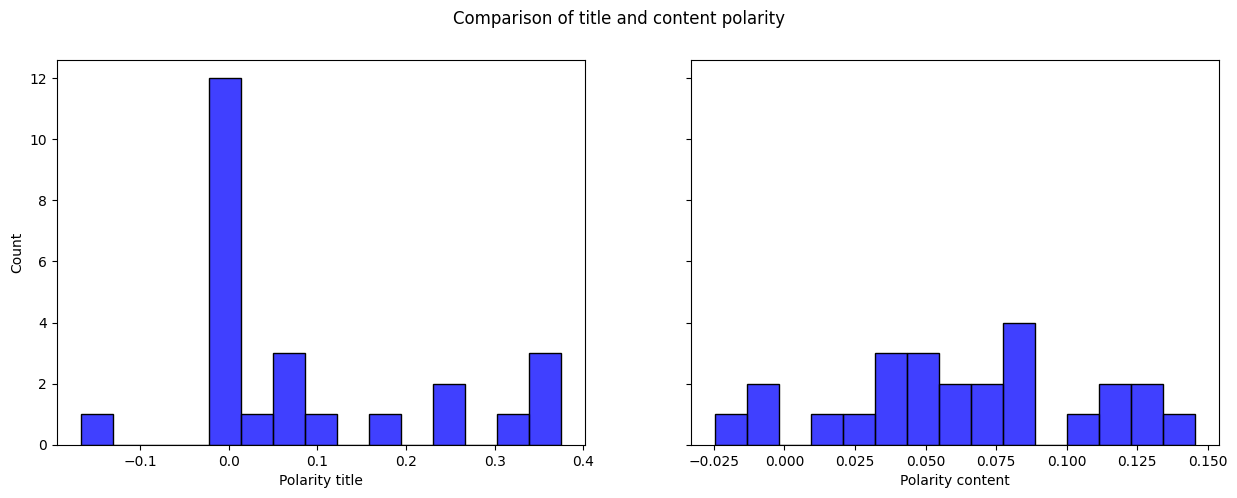

In [22]:
# Convert Spark DataFrame to Pandas DataFrame
articles_with_sentiment_pandas = articles_with_sentiment.select("polarity_title", "polarity_content").toPandas()

# Set up Seaborn style and figure size
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
fig.suptitle('Comparison of title and content polarity')

# Create the scatter plot with Seaborn
sns.histplot(
    ax=axes[0],
    data=articles_with_sentiment_pandas,
    x="polarity_title",
    color="b",
    bins=15
).set(xlabel = "Polarity title")
sns.histplot(
    ax=axes[1],
    data=articles_with_sentiment_pandas,
    x="polarity_content",
    color="b",
    bins=15
).set(xlabel = "Polarity content")

plt.show()

## 1.3 Sentiment analysis using LLMs

In this section, we will explore the use of Large Language Models (LLMs) for text classification tasks. LLMs have revolutionized natural language processing by enabling more accurate and context-aware understanding of text data. This makes packages like TextBlob outdated for more complex tasks. We will utilize the pre-trained FinBERT model from Hugging Face's Transformers library to create embeddings for our news articles. These embeddings will then be used as features in a classification model to predict financing announcements. For sentiment analysis, we will use the Gemma3:4b model to generate sentiment scores for each article. 

**Note:** For the assignment, be sure to make use of LLMs to process the news articles, and if needed, try to limit the computational cost by using a smaller model or limiting the number of requests!


Other features that can be generated by LLMs include:
- Topic Modeling: Extracting underlying topics from a collection of documents to understand the main themes.
- Summarization: Generating concise summaries of longer texts to capture the main points.

### 1.3.1 FinBERT Embeddings

In [23]:
#To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/. This will ensure that the model runs on GPU if available.
import torch

from pyspark.ml.functions import array_to_vector
from transformers import AutoTokenizer, AutoModel

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
# runs long 
# Load the tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModel.from_pretrained("ProsusAI/finbert")
embed_dim = 768  # FinBERT embedding dimension

# Set model to evaluation mode
model.eval()

# Determine device: GPU is preferred if a CUDA-enabled GPU is available. To install torch with cuda support, follow instructions at https://pytorch.org/get-started/locally/
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

In [25]:
def get_embeddings(text):
    if text is None or text == "":
        return None
    
    # Tokenize the input text
    inputs = tokenizer(text, 
                     padding=True, 
                     truncation=True, 
                     max_length=512,
                     return_tensors="pt")
    
    # Move inputs to device
    inputs = {key: val.to(device) for key, val in inputs.items()}
    
    # Generate embeddings without gradient computation
    with torch.no_grad():
        outputs = model(**inputs)

    # Mean pooling - take attention mask into account for correct averaging so we don't include padding tokens
    attention_mask = inputs['attention_mask']
    token_embeddings = outputs.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    embeddings = torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
    
    # Convert to numpy and then to list
    embedding_list = embeddings.cpu().numpy()[0].tolist()
    
    return embedding_list

# Register the function as a UDF
get_embeddings_udf = F.udf(get_embeddings, ArrayType(DoubleType()))

In [26]:
# Apply the UDF to get FinBERT embeddings for the content column
articles_df_with_embeddings = articles_with_sentiment.withColumn("finbert_embeddings", get_embeddings_udf(F.col("content")))

In [27]:
# We need to convert the list of floats to Spark's Vector type, but first filter out observations without embeddings
articles_df_with_embeddings = articles_df_with_embeddings.filter(F.col("finbert_embeddings").isNotNull())
articles_df_with_embeddings = articles_df_with_embeddings.withColumn("finbert_embeddings", array_to_vector(F.col("finbert_embeddings")))
articles_df_with_embeddings.cache().show()

+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------------+--------------------+-------------------+--------------------+--------------------+--------------------+
|             content|      date|               title|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|       text_features|  finbert_embeddings|
+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------------+--------------------+-------------------+--------------------+--------------------+--------------------+
|mcewen inc and ca...|2025-07-28|mcewen inc and ca...|[mce

### 1.3.2 Ollama sentiment analysis

1) First type in the terminal: ollama pull gemma3:4b
2) start ollama service in terminal: ollama serve 
3) In another terminal, verify: ollama list should provide a gemma 3:4b

In [28]:
#4 after downloading and starting ollama, run this 
import requests
import ollama

def setup_and_test_ollama():
    print("=" * 60)
    print("SETTING UP OLLAMA")
    print("=" * 60)
    
    # Step 1: Check if Ollama is running
    try:
        response = requests.get('http://localhost:11434/api/tags', timeout=5)
        if response.status_code == 200:
            print("✅ Ollama service is running")
        else:
            print(f"❌ Ollama API error: {response.status_code}")
            return False
    except requests.exceptions.ConnectionError:
        print("❌ Ollama service not running. Run 'ollama serve' in terminal")
        return False
    
    # Step 2: Check available models
    try:
        response = requests.get('http://localhost:11434/api/tags')
        models = response.json().get('models', [])
        
        if not models:
            print("❌ No models found. Download one with: ollama pull gemma3:4b")
            return False
        
        print(f"✅ Found {len(models)} model(s):")
        for model in models:
            print(f"   - {model.get('name')}")
        
        # Step 3: Check if gemma3:4b is available
        model_names = [m.get('name') for m in models]
        if 'gemma3:4b' not in model_names:
            print("❌ gemma3:4b not found. Download it with: ollama pull gemma3:4b")
            
            # Try to use any available model
            available_model = model_names[0]
            print(f"⚠️  Using available model: {available_model} instead")
            MODEL_NAME = available_model
        else:
            print("✅ gemma3:4b is available!")
            MODEL_NAME = 'gemma3:4b'
        
        # Step 4: Test the model
        print("\n🧪 Testing model with simple query...")
        try:
            response = ollama.chat(
                model=MODEL_NAME,
                messages=[{'role': 'user', 'content': 'What is 2+2?'}],
                options={'temperature': 0.1}
            )
            print(f"✅ Model test successful!")
            print(f"   Response: {response['message']['content'].strip()}")
            return True
        except Exception as e:
            print(f"❌ Model test failed: {e}")
            return False
            
    except Exception as e:
        print(f"❌ Error checking models: {e}")
        return False

# Run the setup
setup_and_test_ollama()

SETTING UP OLLAMA
✅ Ollama service is running
✅ Found 1 model(s):
   - gemma3:4b
✅ gemma3:4b is available!

🧪 Testing model with simple query...
✅ Model test successful!
   Response: 2 + 2 = 4


True

In [29]:
# pass the name (and configuration) of the model from the ollama website
MODEL_NAME = 'gemma3:4b'

try:
    import ollama
    
    # simple prompt to test general knowledge
    response = ollama.chat(model=MODEL_NAME, 
                           messages=[
                            {
                                'role': 'user',
                                'content': 'Explain what NLP is in one sentence.'
                            }
                        ])
    
    # print response
    print("Ollama is working! The model is running locally on your machine!")
    print('='*50)
    print(f"RESPONSE FROM {MODEL_NAME.upper()}:")
    print(response['message']['content'])
    
except Exception as e:
    print(f"Could not connect to Ollama: ")
    print("\nMake sure:")
    print("1. Ollama application is installed")
    print("2. Python package is installed (pip install ollama)")
    print(f"3. You've downloaded a model (e.g., 'ollama pull {MODEL_NAME}')")
    print("4. Ollama is running (check terminal: 'ollama serve')")

Ollama is working! The model is running locally on your machine!
RESPONSE FROM GEMMA3:4B:
Natural Language Processing (NLP) is a field of computer science focused on enabling computers to understand, interpret, and generate human language.


In [30]:
# Function to get sentiment using ollama
def get_ollama_sentiment(text):
    try:
        import ollama
        
        prompt = f"""Provide the sentiment of the following text as a single numerical value between -1 and 1, 
        where -1 is very negative, 0 is neutral, and 1 is very positive, from an investment perspective. Only provide the numerical value, 
        I don't want any explanation or other text answer.\n\nText: '{text}'"""
        
        response = ollama.chat(model=MODEL_NAME, 
                               messages=[
                                {
                                    'role': 'user',
                                    'content': prompt
                                }
                            ])
        
        return (response['message']['content'].strip())
    except Exception as e:
        return None
    
# Register udf
get_ollama_sentiment_udf = F.udf(get_ollama_sentiment, StringType())

In [31]:
# Test the prompt first before applying to all articles
articles_df_with_embeddings_pandas = articles_df_with_embeddings.toPandas()
print(get_ollama_sentiment(articles_df_with_embeddings_pandas['content'].iloc[0]))

0.85


In [32]:
# Apply ollama sentiment analysis
articles_with_ollama_sentiment = articles_df_with_embeddings.withColumn("ollama_sentiment", get_ollama_sentiment_udf(F.col("content")))
articles_with_ollama_sentiment.cache().show()

+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------------+--------------------+-------------------+--------------------+--------------------+--------------------+----------------+
|             content|      date|               title|     title_tokenized|   content_tokenized|num_words_title|num_words_content|period_start|period_end|biweekly_period|next_announcement|      polarity_title|    polarity_content| subjectivity_title|subjectivity_content|       text_features|  finbert_embeddings|ollama_sentiment|
+--------------------+----------+--------------------+--------------------+--------------------+---------------+-----------------+------------+----------+---------------+-----------------+--------------------+--------------------+-------------------+--------------------+--------------------+--------------------+----------------+
|mcewen

In [33]:
# Aggregate features by biweekly period
basetable = articles_with_ollama_sentiment.groupBy("period_start", "period_end", "biweekly_period", "next_announcement") \
    .agg(
        F.count("text_features").alias("num_articles"),
        F.avg("num_words_title").alias("avg_num_words_title"),
        F.avg("num_words_content").alias("avg_num_words_content"),
        F.avg("polarity_title").alias("avg_polarity_title"),
        F.avg("polarity_content").alias("avg_polarity_content"),
        F.avg("subjectivity_title").alias("avg_subjectivity_title"),
        F.avg("subjectivity_content").alias("avg_subjectivity_content"),
        F.last("finbert_embeddings").alias("finbert_embeddings"), # we use last for simplicity here, 
        # because averaging Vector types in Spark isn't possible. You can however do this using custom functions
        F.avg("ollama_sentiment").alias("avg_ollama_sentiment")
    ) \
    .orderBy("period_start")

basetable.show()

+------------+----------+---------------+-----------------+------------+-------------------+---------------------+--------------------+--------------------+----------------------+------------------------+--------------------+--------------------+
|period_start|period_end|biweekly_period|next_announcement|num_articles|avg_num_words_title|avg_num_words_content|  avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|  finbert_embeddings|avg_ollama_sentiment|
+------------+----------+---------------+-----------------+------------+-------------------+---------------------+--------------------+--------------------+----------------------+------------------------+--------------------+--------------------+
|  2024-10-10|2024-10-23|             P0|                0|           1|               26.0|               1091.0| 0.04545454545454545| 0.05114137405804072|   0.48484848484848486|     0.36272947731281063|[-0.0899918898940...|                0.85|
|  2024-11-0

## 2. Modeling

In this section, we’ll train some basic predictive models to predict financing announcements. We’ll use the first 8 months of our dataset for training, reserving the final 3 months for model evaluation. By relying exclusively on lagged variables as predictors, we ensure that the model only uses historical information to make forward-looking predictions—mirroring the real-world constraint of forecasting based solely on past data.

When working with time series data, particularly in stock price analysis, it’s essential to maintain the temporal order of observations. Randomly splitting the data into training and testing sets can lead to information leakage, as future information may inadvertently influence the model during training. To prevent this, a time-based split should be used instead.

### 2.1 Time-based Split
A time-based split involves using the earlier portion of the dataset for training and reserving the later portion for testing. This approach mirrors a real-world scenario in which we predict future announcements based solely on historical data, ensuring that our model remains grounded in past information while evaluating its ability to forecast what comes next.

In [34]:
# Use the first 2/3 of the data for training and the last 1/3 for testing
train_size = int(basetable.count() * 0.67)
train_df = basetable.limit(train_size)

# Use the remaining data for testing
test_df = basetable.subtract(train_df)

### 2.2. Check Missing Values

In [35]:
# get all numeric columns
numeric_cols = [c for c, t in train_df.dtypes if isinstance(train_df.schema[c].dataType, NumericType)]

# count null values in each column
null_counts_train = train_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_train.show()

null_counts_test = test_df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in numeric_cols])
null_counts_test.show()

+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|next_announcement|num_articles|avg_num_words_title|avg_num_words_content|avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|avg_ollama_sentiment|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|                0|           0|                  0|                    0|                 0|                   0|                     0|                       0|                   0|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+



25/12/04 12:37:44 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|next_announcement|num_articles|avg_num_words_title|avg_num_words_content|avg_polarity_title|avg_polarity_content|avg_subjectivity_title|avg_subjectivity_content|avg_ollama_sentiment|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+
|                0|           0|                  0|                    0|                 0|                   0|                     0|                       0|                   0|
+-----------------+------------+-------------------+---------------------+------------------+--------------------+----------------------+------------------------+--------------------+



### 2.3 Check Label Distribution in Train & Test set

In [36]:
# check label distribution in train test
train_label_distr = train_df.groupBy('next_announcement').count()
train_label_distr.show()

# check label distribution in test test
test_label_distr = test_df.groupBy('next_announcement').count()
test_label_distr.show()

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                0|    9|
|                1|    1|
+-----------------+-----+

+-----------------+-----+
|next_announcement|count|
+-----------------+-----+
|                1|    1|
|                0|    4|
+-----------------+-----+



### 2.4 Scale Numeric Features

In [37]:
exclude_columns = ["biweekly_period", "period_start", "period_end", "next_announcement"]
feature_columns = [col for col in train_df.columns if col not in exclude_columns]
VA = VectorAssembler(inputCols=feature_columns, outputCol="features", handleInvalid = "skip")

In [38]:
# define the standardizer (standard normal)
SS = StandardScaler(inputCol="features", outputCol="featuresNorm", withMean=False, withStd=True)

### 2.5 Regularized Logistic Regression

In [39]:

# define logistic regression model
LR = LogisticRegression(featuresCol="featuresNorm", labelCol="next_announcement", elasticNetParam=0.8, regParam=0.001)

# fit model on train
lr_pipeline = Pipeline(stages=[VA, SS, LR])

# model training
lr_model = lr_pipeline.fit(train_df)

In [40]:
# predictions
lr_predictions = lr_model.transform(test_df)

In [41]:
# show predictions
lr_predictions.select("period_start", "period_end", "next_announcement", "prediction").show()

+------------+----------+-----------------+----------+
|period_start|period_end|next_announcement|prediction|
+------------+----------+-----------------+----------+
|  2025-05-08|2025-05-21|                0|       0.0|
|  2025-05-22|2025-06-04|                0|       0.0|
|  2025-06-05|2025-06-18|                1|       0.0|
|  2025-06-19|2025-07-02|                0|       0.0|
|  2025-07-17|2025-07-30|                0|       0.0|
+------------+----------+-----------------+----------+



In [42]:
def calculate_classification_metrics(predictions, label_col, prediction_col):
    # calculate true positives, true negatives, false positives, false negatives
    tp = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 1)).count()
    tn = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 0)).count()
    fp = predictions.filter((F.col(label_col) == 0) & (F.col(prediction_col) == 1)).count()
    fn = predictions.filter((F.col(label_col) == 1) & (F.col(prediction_col) == 0)).count()

    # calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # calculate precision
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0  
    
    # calculate recall
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0.0  
    
    # calculate F1 measure
    f1_measure = 2 * (precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0  

    # print the metrics
    print(f"Accuracy: {accuracy}")
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"F1 measure: {f1_measure}")
    
    return accuracy, precision, recall, f1_measure

In [43]:
# get metrics
lr_accuracy, lr_precision, lr_recall, lr_f1_measure = calculate_classification_metrics(lr_predictions, 'next_announcement', 'prediction')

Accuracy: 0.8
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [44]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

lr_AUC = evaluator.evaluate(lr_predictions)
print(f"AUC: {lr_AUC:.4f}")

AUC: 0.7500


### 2.6 Random forest

In [45]:
# define random forest model
RF = RandomForestClassifier(featuresCol="featuresNorm", labelCol="next_announcement", numTrees=100)

# fit model on train
rf_pipeline = Pipeline(stages=[VA, SS, RF])

# Model training
rf_model = rf_pipeline.fit(train_df)

25/12/04 12:37:49 WARN DecisionTreeMetadata: DecisionTree reducing maxBins from 32 to 10 (= number of training instances)


In [46]:
# predictions
rf_predictions = rf_model.transform(test_df)

In [47]:
# show predictions
rf_predictions.select("period_start", "period_end", "next_announcement", "prediction").show()

+------------+----------+-----------------+----------+
|period_start|period_end|next_announcement|prediction|
+------------+----------+-----------------+----------+
|  2025-05-08|2025-05-21|                0|       0.0|
|  2025-05-22|2025-06-04|                0|       0.0|
|  2025-06-05|2025-06-18|                1|       0.0|
|  2025-06-19|2025-07-02|                0|       0.0|
|  2025-07-17|2025-07-30|                0|       0.0|
+------------+----------+-----------------+----------+



In [48]:
# get metrics
rf_accuracy, rf_precision, rf_recall, rf_f1_measure = calculate_classification_metrics(rf_predictions, 'next_announcement', 'prediction')

Accuracy: 0.8
Precision: 0
Recall: 0.0
F1 measure: 0.0


In [49]:
# get AUC
evaluator = BinaryClassificationEvaluator(labelCol="next_announcement", 
                                          rawPredictionCol="probability", 
                                          metricName="areaUnderROC")

rf_AUC = evaluator.evaluate(rf_predictions)
print(f"AUC: {rf_AUC:.4f}")

AUC: 0.7500


In [50]:
# check which algorithm is the best
print("LOGISTIC REGRESSION:")
print('  ACCURACY   : %g' % lr_accuracy)
print('  PRECISION  : %g' % lr_precision)
print('  RECALL     : %g' % lr_recall)
print('  AUC        : %g' % lr_AUC)
print('  F1         : %g' % lr_f1_measure)
print("------------------")
print("RANDOM FOREST:")
print('  ACCURACY   : %g' % rf_accuracy)
print('  PRECISION  : %g' % rf_precision)
print('  RECALL     : %g' % rf_recall)
print('  AUC        : %g' % rf_AUC)
print('  F1         : %g' % rf_f1_measure)

LOGISTIC REGRESSION:
  ACCURACY   : 0.8
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.75
  F1         : 0
------------------
RANDOM FOREST:
  ACCURACY   : 0.8
  PRECISION  : 0
  RECALL     : 0
  AUC        : 0.75
  F1         : 0


# Next steps group assignment

**What you can do after this demo:**

    - Cleaning text
    - Extracting keywords
    - Creating NLP pipelines
    - Finetuning NLP pipelines
    - Using methods to aggregate Price history and News data
    - Experiment with different LLMs to generate features
    - ...

Get creative and get as much value out of the data as possible!